<a href="https://colab.research.google.com/github/Abhiroop25902/Major-Project/blob/main/cnn_model/4_image_resize_cnn_rotated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv('./dataset.csv')

In [4]:
# Step 1 -> convert text to numbers using textVocab
from tensorflow.keras.layers import TextVectorization

vectorize_layer = TextVectorization(
    max_tokens=100,
    split="character",
    output_mode = 'int',
)

vectorize_layer.adapt(df.encrypt.to_list())

In [5]:
vectorized_strings = np.array([vectorize_layer(s).numpy() for s in df['encrypt']], dtype='object')
vectorized_strings.shape

(34075,)

In [12]:
images = np.array(
    [[np.roll(vector, idx) for idx in range(len(vector))] for vector in vectorized_strings]
, dtype='object')
images.shape

(34075,)

In [13]:
import cv2

X = np.array(
    [cv2.resize(np.array(image, dtype='uint8'), dsize=(64,64)) for image in images]
)
X.shape

(34075, 64, 64)

In [14]:
X = X.reshape(-1,64,64,1)
X.shape

(34075, 64, 64, 1)

In [15]:
input_shape = X[0].shape
input_shape

(64, 64, 1)

In [16]:
y = pd.get_dummies(df[['algorithm']])

In [17]:
X.shape

(34075, 64, 64, 1)

In [18]:
y.shape

(34075, 5)

In [19]:
from sklearn.model_selection import train_test_split
x_train, x_rem, y_train, y_rem = train_test_split(X, y, test_size=0.2, random_state=42)
x_val, x_test, y_val, y_test = train_test_split(x_rem, y_rem, test_size=0.2, random_state=42)

# Training

In [20]:
import tensorflow as tf
from tensorflow.keras.layers import Lambda, Conv2D, \
BatchNormalization, MaxPool2D, Reshape, Flatten, Dense, Dropout


model = tf.keras.models.Sequential()

model.add(tf.keras.Input(shape=input_shape))

model.add(Conv2D(16, (3,3), activation='relu'))
model.add(MaxPool2D())
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Conv2D(32, (3,3), activation='relu'))
model.add(MaxPool2D())
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Conv2D(64, (3,3), activation='relu'))
model.add(MaxPool2D())
model.add(BatchNormalization())

model.add(Flatten())

model.add(Dropout(0.1))
model.add(Dense(units=1024, activation='relu'))
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Dense(units=256, activation='relu'))
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Dense(units=64, activation='relu'))
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Dense(units=16, activation='relu'))
model.add(BatchNormalization())

model.add(Dense(units=5, activation='softmax'))

In [21]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 62, 62, 16)        160       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 31, 31, 16)       0         
 )                                                               
                                                                 
 batch_normalization (BatchN  (None, 31, 31, 16)       64        
 ormalization)                                                   
                                                                 
 dropout (Dropout)           (None, 31, 31, 16)        0         
                                                                 
 conv2d_1 (Conv2D)           (None, 29, 29, 32)        4640      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 14, 14, 32)       0

In [22]:
from tensorflow.keras.callbacks import EarlyStopping

model.compile(
    loss="categorical_crossentropy", metrics=["accuracy"]
)
callback = [
    EarlyStopping(
        monitor='val_accuracy',
        patience=10,
        restore_best_weights=True
    )
]

history = model.fit(
    x_train,
    y_train,
    epochs=10000,
    validation_data=(x_val, y_val),
    callbacks=callback,
)

Epoch 1/10000
852/852 [==============================] - 19s 11ms/step - loss: 1.2494 - accuracy: 0.4601 - val_loss: 1.1617 - val_accuracy: 0.5029
Epoch 2/10000
852/852 [==============================] - 9s 10ms/step - loss: 1.1409 - accuracy: 0.5082 - val_loss: 2.1417 - val_accuracy: 0.3034
Epoch 3/10000
852/852 [==============================] - 9s 10ms/step - loss: 1.0971 - accuracy: 0.5298 - val_loss: 1.2288 - val_accuracy: 0.4848
Epoch 4/10000
852/852 [==============================] - 9s 10ms/step - loss: 1.0689 - accuracy: 0.5421 - val_loss: 1.1502 - val_accuracy: 0.4982
Epoch 5/10000
852/852 [==============================] - 9s 10ms/step - loss: 1.0296 - accuracy: 0.5651 - val_loss: 1.0711 - val_accuracy: 0.5396
Epoch 6/10000
852/852 [==============================] - 9s 10ms/step - loss: 0.9998 - accuracy: 0.5800 - val_loss: 1.2813 - val_accuracy: 0.4795
Epoch 7/10000
852/852 [==============================] - 9s 11ms/step - loss: 0.9665 - accuracy: 0.5965 - val_loss: 1.4585 

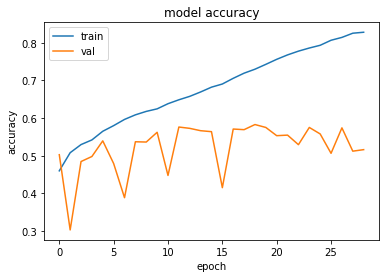

In [23]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

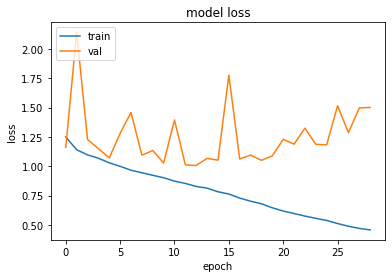

In [24]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

In [25]:
model.save('./model_rotated_matrix')

In [26]:
test_loss, test_acc = model.evaluate(x_val, y_val)
print(f"test_loss={test_loss}, test_acc={test_acc}")

171/171 [==============================] - 1s 4ms/step - loss: 1.0510 - accuracy: 0.5829
test_loss=1.0510302782058716, test_acc=0.5829053521156311
